# 03 · From probabilities to money: profit curve and sensitivity analysis

**Question:** whom should the retention team contact, and how many?
Answer by **expected profit**, not by F1 or a 0.5 threshold.

> ⚠️ **All money figures rest on assumptions** in `config/config.yaml →
> business`. The dataset has no revenue or cost data. Treat the absolute
> dollar amounts as illustrative; the *method* and the *relative*
> comparisons are the deliverable.

In [1]:
import sys
from dataclasses import replace
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import f1_score

from src.config import load_config, path, set_seed
from src import business as B
from src.plots import ACCENT, GOOD, MUTED, NEUTRAL, RISK, save, save_table, setup_style

cfg = load_config()
SEED = set_seed()
setup_style()
pd.set_option("display.width", 160, "display.max_columns", 30)

A = B.Assumptions.from_config(cfg)
test = pd.read_csv(path("processed") / "test_predictions.csv")
oof = pd.read_csv(path("processed") / "train_oof_predictions.csv")
full = pd.read_csv(path("raw_data"))  # only for CLV of train rows below
y, p = test["churned"].to_numpy(), test["proba"].to_numpy()
A

Assumptions(annual_interchange_rate=0.015, revolving_margin_rate=0.15, clv_horizon_years=2, clv_floor=150, contact_cost=15, incentive_cost=40, incentive_accept_rate=0.5, retention_success_rate=0.25)

## 1. Assumptions (explicit, in config)

| Assumption | Value | Why this value / how weak it is |
|---|---|---|
| Customer value (CLV) | 1.5% interchange × yearly spend + 15% margin × revolving balance, × 2 years, floor $150 | Typical card economics; **weak** — no real P&L data |
| Contact cost | $15 | Call-centre minute cost + CRM ops; moderate |
| Incentive | $40, accepted by 50% of contacted | Fee waiver / cashback; moderate |
| Retention success rate | 25% of contacted churners stay | Literature range 10–40%; **weakest** assumption → measure it with the A/B test |

Cost per contact = 15 + 0.5 × 40 = **$35**.

In [2]:
test["clv"] = B.customer_value(test, A)
print(f"cost per contact: ${A.cost_per_contact:.0f}")
print(test.groupby("churned")["clv"].describe()[["mean", "25%", "50%", "75%"]].round(0))

cost per contact: $35
          mean    25%    50%    75%
churned                            
0        517.0  356.0  520.0  692.0
1        342.0  150.0  197.0  518.0


Note: churners are worth *less* on average (they spend less) — so ranking
only by churn probability spends money on low-value customers. We compare
two rankings:
* **by probability** — classic churn targeting;
* **by expected profit** = P(churn) × success rate × CLV − cost.

## 2. Profit curves on the hold-out set

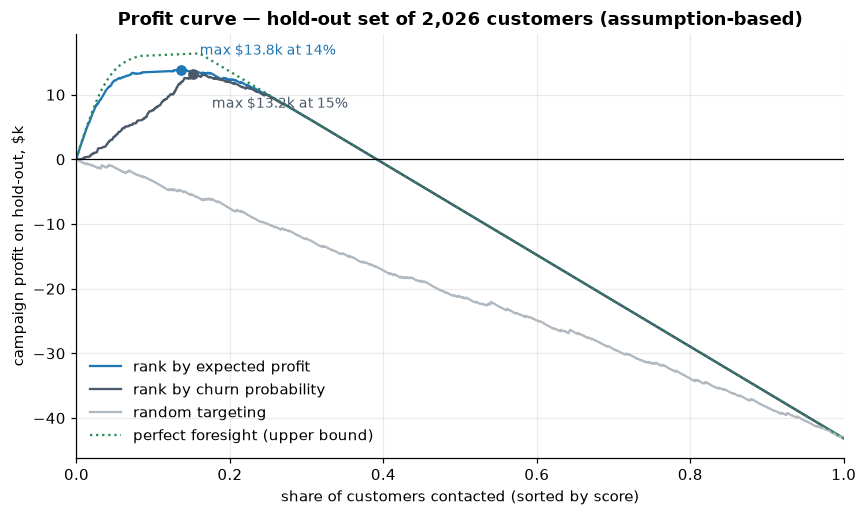

,n_contacted,share_contacted,profit,churners_reached,profit_if_contact_all
rank by expected profit,277.0,0.137,13832.028,258.0,-43148.788
rank by churn probability,309.0,0.153,13186.912,291.0,-43148.788
random targeting,0.0,0.000,0.000,0.0,-43148.788


In [3]:
rng = np.random.default_rng(SEED)
ev = B.expected_profit(p, test["clv"].to_numpy(), A)
curves = {
    "rank by expected profit": B.profit_curve(y, ev, test["clv"], A),
    "rank by churn probability": B.profit_curve(y, p, test["clv"], A),
    "random targeting": B.profit_curve(y, rng.random(len(y)), test["clv"], A),
}
# Perfect foresight = upper bound: contact only real churners with positive value.
oracle = B.profit_curve(y, y * test["clv"].to_numpy(), test["clv"], A)

fig, ax = plt.subplots(figsize=(9, 5))
for (name, c), color in zip(curves.items(), [ACCENT, NEUTRAL, MUTED]):
    ax.plot(c.share_contacted, c.profit / 1000, color=color, label=name)
    b = B.best_point(c)
    if name != "random targeting":
        ax.scatter(b.share_contacted, b.profit / 1000, color=color, zorder=5)
        offset = (12, 10) if name == "rank by expected profit" else (12, -22)
        ax.annotate(f"max ${b.profit/1000:.1f}k at {b.share_contacted:.0%}",
                    (b.share_contacted, b.profit / 1000), xytext=offset,
                    textcoords="offset points", fontsize=9, color=color)
ax.plot(oracle.share_contacted, oracle.profit / 1000, color=GOOD, ls=":", label="perfect foresight (upper bound)")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("share of customers contacted (sorted by score)")
ax.set_ylabel("campaign profit on hold-out, $k")
ax.set_title(f"Profit curve — hold-out set of {len(y):,} customers (assumption-based)")
ax.set_xlim(0, 1)
ax.legend(loc="lower left")
save(fig, "business_profit_curve")
plt.show()

summary = pd.DataFrame({name: B.best_point(c) for name, c in curves.items()}).T
summary["profit_if_contact_all"] = curves["random targeting"].profit.iloc[-1]
summary.round(3)

## 3. Choosing the campaign size *without* peeking at the test set
Picking the maximum of the test curve and reporting it as the result is
optimistic (we would be tuning on test). Instead:
1. **Rule A (no tuning):** contact everyone with positive expected profit,
   `E[profit] > 0`. Needs only calibrated probabilities and the assumptions.
2. **Rule B:** choose the top-k% that maximises profit on the **train
   out-of-fold** predictions, then apply that k to the test set.
Compare against common but wrong choices: threshold 0.5 and F1-optimal threshold.

In [4]:
train_rows = full.set_index("CLIENTNUM").loc[oof["clientnum"]]
train_feat = pd.DataFrame({"total_trans_amt": train_rows["Total_Trans_Amt"].to_numpy(),
                           "total_revolving_bal": train_rows["Total_Revolving_Bal"].to_numpy()})
oof_clv = B.customer_value(train_feat, A).to_numpy()
oof_ev = B.expected_profit(oof["proba"].to_numpy(), oof_clv, A)
oof_curve = B.profit_curve(oof["churned"].to_numpy(), oof_ev, oof_clv, A)
k_star = B.best_point(oof_curve)["share_contacted"]
n_k = int(round(k_star * len(y)))
print(f"Optimal share on TRAIN (OOF): {k_star:.1%}")

# F1-optimal threshold, also chosen on train OOF
ths = np.linspace(0.05, 0.95, 91)
f1s = [f1_score(oof["churned"], oof["proba"] >= t) for t in ths]
t_f1 = float(ths[int(np.argmax(f1s))])

ev_curve = curves["rank by expected profit"]
decisions = pd.DataFrame([
    {"rule": "Rule A: E[profit] > 0", **B.profit_at_threshold(y, ev, test["clv"], 0.0, A)},
    {"rule": f"Rule B: top {k_star:.1%} by E[profit] (k chosen on train)", "threshold": np.nan,
     "n_contacted": n_k, "share_contacted": n_k / len(y), "profit": float(ev_curve.loc[n_k, "profit"])},
    {"rule": "P(churn) >= 0.5", **B.profit_at_threshold(y, p, test["clv"], 0.5, A)},
    {"rule": f"F1-optimal threshold ({t_f1:.2f})", **B.profit_at_threshold(y, p, test["clv"], t_f1, A)},
    {"rule": "Contact everyone", **B.profit_at_threshold(y, p, test["clv"], -1, A)},
    {"rule": "Upper bound: max of test curve (optimistic)", "threshold": np.nan,
     "n_contacted": int(B.best_point(ev_curve)["n_contacted"]),
     "share_contacted": B.best_point(ev_curve)["share_contacted"],
     "profit": B.best_point(ev_curve)["profit"]},
])
contacted = ev > 0
decisions["churners_reached"] = [
    int(y[contacted].sum()),
    int(y[np.argsort(-ev, kind="stable")[:n_k]].sum()),
    int(y[p >= 0.5].sum()), int(y[p >= t_f1].sum()), int(y.sum()),
    int(ev_curve.loc[int(B.best_point(ev_curve)["n_contacted"]), "churners_reached"]),
]
decisions["profit_per_10k_customers"] = decisions["profit"] / len(y) * 10_000
save_table(decisions, "business_decisions")
decisions.round(3)

Optimal share on TRAIN (OOF): 14.9%


,rule,threshold,n_contacted,share_contacted,profit,churners_reached,profit_per_10k_customers
0,Rule A: E[profit] > 0,0.00,293,0.145,13708.670,269,67663.722
1,Rule B: top 14.9% by E[profit] (k chosen on tr...,NaN,301,0.149,13578.670,273,67022.063
2,P(churn) >= 0.5,0.50,306,0.151,12973.260,289,64033.860
3,F1-optimal threshold (0.38),0.38,322,0.159,12950.567,293,63921.853
4,Contact everyone,-1.00,2026,1.000,-43148.788,325,-212975.259
5,Upper bound: max of test curve (optimistic),NaN,277,0.137,13832.028,258,68272.594


**Takeaways**
* Rule A (`E[profit] > 0`) and Rule B (k chosen on train) land within ~2%
  of the optimistic test-curve maximum — the decision generalises.
* Contacting everyone **loses money** (≈ −$213k per 10k customers): most
  customers would stay anyway and each contact costs $35.
* **Honest note:** threshold 0.5 and the F1-optimal threshold are only ~5%
  worse here. That is a property of this dataset — the model separates the
  classes so sharply that almost any sensible cut-off selects the same
  ~15% of customers. The profit rule earns its keep when the economics
  change: it re-sizes the campaign automatically when costs or CLV move,
  while a fixed 0.5 cut-off cannot react at all (sensitivity below).

### How flat is the curve near the top, and when does the campaign stop paying?

In [5]:
best = B.best_point(ev_curve)
within5 = ev_curve[ev_curve.profit >= 0.95 * best.profit]
target_mask = ev > 0
saved_value = (y[target_mask] * test["clv"].to_numpy()[target_mask]).sum()
break_even_success = target_mask.sum() * A.cost_per_contact / saved_value
robust = pd.DataFrame([{
    "flat_band_low_share": within5.share_contacted.min(),
    "flat_band_high_share": within5.share_contacted.max(),
    "break_even_success_rate_base_plan": break_even_success,
    "assumed_success_rate": A.retention_success_rate,
}])
save_table(robust, "business_robustness")
print(f"Any campaign between {within5.share_contacted.min():.1%} and {within5.share_contacted.max():.1%} "
      f"of customers is within 5% of the best profit.")
print(f"The Rule-A campaign breaks even if at least {break_even_success:.1%} of contacted churners are saved "
      f"(assumed: {A.retention_success_rate:.0%}).")

Any campaign between 7.1% and 17.8% of customers is within 5% of the best profit.
The Rule-A campaign breaks even if at least 10.7% of contacted churners are saved (assumed: 25%).


## 4. Sensitivity analysis: what if the assumptions are wrong by ±50%?

In [6]:
mults = cfg["business"]["sensitivity_multipliers"]
sens = B.sensitivity_one_way(test, y, p, A, mults)
save_table(sens, "business_sensitivity")
base_profit = sens.query("multiplier == 1.0").optimal_profit.iloc[0]
pivot_profit = sens.pivot(index="assumption", columns="multiplier", values="optimal_profit")
pivot_share = sens.pivot(index="assumption", columns="multiplier", values="optimal_share_contacted")
print("Optimal campaign profit on hold-out ($):")
display(pivot_profit.round(0))
print("Optimal share of customers to contact:")
display(pivot_share.round(3))

Optimal campaign profit on hold-out ($):


multiplier,0.50,0.75,1.00,1.25,1.50
assumption,,,,,
clv (value of a customer),4336.0,8741.0,13832.0,19815.0,26208.0
contact_cost,16010.0,14895.0,13832.0,12826.0,12271.0
incentive_cost,16880.0,15256.0,13832.0,12641.0,11901.0
retention_success_rate,4336.0,8741.0,13832.0,19815.0,26208.0


Optimal share of customers to contact:


multiplier,0.50,0.75,1.00,1.25,1.50
assumption,,,,,
clv (value of a customer),0.049,0.073,0.137,0.156,0.175
contact_cost,0.156,0.143,0.137,0.073,0.073
incentive_cost,0.175,0.143,0.137,0.073,0.073
retention_success_rate,0.049,0.073,0.137,0.156,0.175


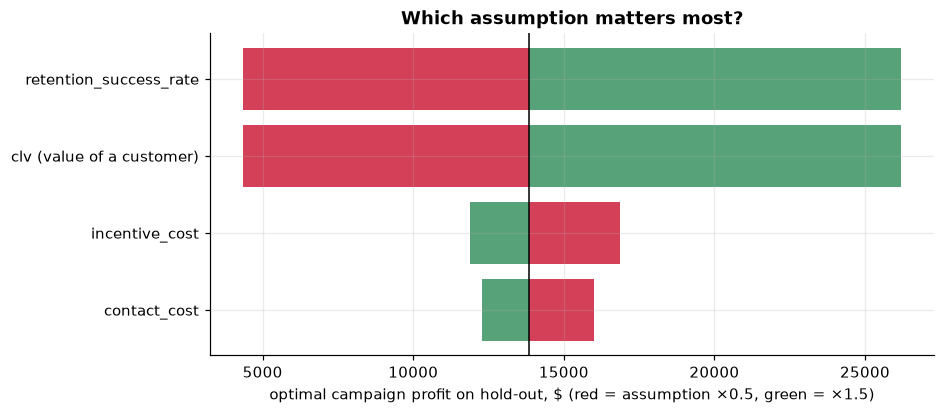

In [7]:
# Tornado chart: profit range when each assumption moves -50% / +50%
lo = sens.query("multiplier == 0.5").set_index("assumption").optimal_profit
hi = sens.query("multiplier == 1.5").set_index("assumption").optimal_profit
tor = pd.DataFrame({"low": lo, "high": hi})
tor["range"] = (tor.high - tor.low).abs()
tor = tor.sort_values("range")
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for i, (name, r) in enumerate(tor.iterrows()):
    ax.barh(i, r.low - base_profit, left=base_profit, color=RISK, alpha=0.8)
    ax.barh(i, r.high - base_profit, left=base_profit, color=GOOD, alpha=0.8)
ax.set_yticks(range(len(tor)), tor.index)
ax.axvline(base_profit, color="black", lw=1)
ax.set_xlabel("optimal campaign profit on hold-out, $ (red = assumption ×0.5, green = ×1.5)")
ax.set_title("Which assumption matters most?")
save(fig, "business_tornado")
plt.show()

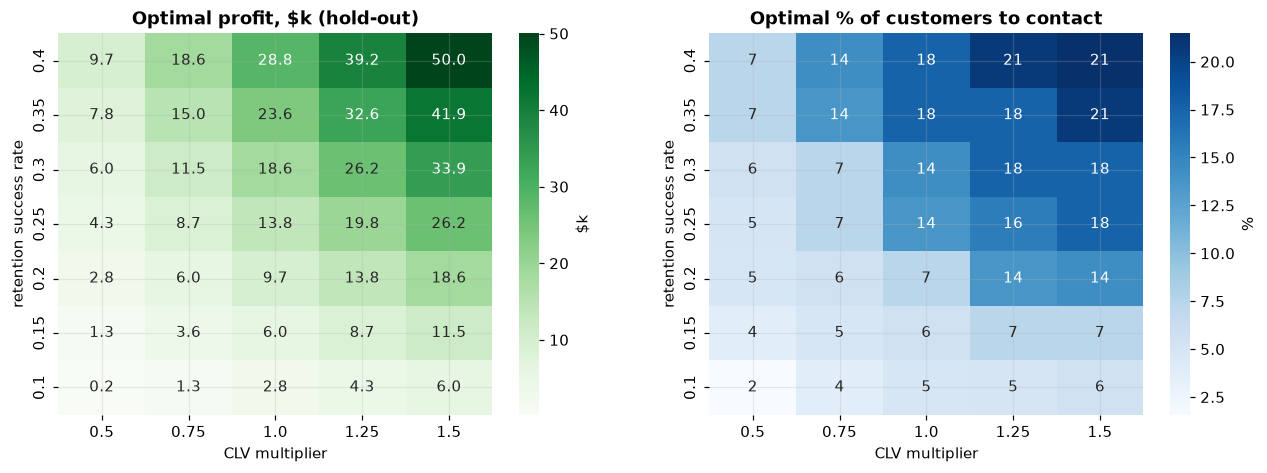

In [8]:
grid = B.sensitivity_grid(test, y, p, A,
                          success_rates=[0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40],
                          clv_scales=[0.5, 0.75, 1.0, 1.25, 1.5])
save_table(grid, "business_sensitivity_grid")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
hm1 = grid.pivot(index="retention_success_rate", columns="clv_scale", values="optimal_profit")
hm2 = grid.pivot(index="retention_success_rate", columns="clv_scale", values="optimal_share_contacted")
sns.heatmap(hm1 / 1000, annot=True, fmt=".1f", cmap="Greens", ax=axes[0], cbar_kws={"label": "$k"})
axes[0].set_title("Optimal profit, $k (hold-out)")
sns.heatmap(hm2 * 100, annot=True, fmt=".0f", cmap="Blues", ax=axes[1], cbar_kws={"label": "%"})
axes[1].set_title("Optimal % of customers to contact")
for ax in axes:
    ax.set_xlabel("CLV multiplier")
    ax.set_ylabel("retention success rate")
    ax.invert_yaxis()
save(fig, "business_sensitivity_grid")
plt.show()

**Reading the sensitivity analysis**
* **Retention success rate and CLV move profit the most**, and they move it
  identically: in this model the benefit is P × success × CLV, so ×0.5 on
  either one is the same scenario. Profit ranges from ~$4k to ~$26k on the
  hold-out (≈ $21k–$129k per 10k customers). Costs matter much less.
* The **optimal size jumps** (≈ 5% to 17.5% of customers) because the curve
  is flat near the top — many sizes give nearly the same profit. So the
  size is not "robust" as a point, but *picking a size in the flat band is
  cheap*: `profit_of_base_plan` shows that keeping the base-case size loses
  little versus re-optimising, except when value is halved (≈ $2.1k vs
  $4.3k) — then a smaller, high-value-only campaign is clearly better.
* Even the pessimistic corner (10% success, CLV ×0.5) stays slightly
  positive *if* the campaign is re-sized; the base-plan break-even save rate
  is ~11%. That is the key risk to communicate.

**The single most valuable next step is to measure the retention success
rate with an A/B test** — it is both the most influential and the least
known assumption. → notebook 04.

In [9]:
# Save the campaign list (Rule A) for the cross-sell notebook.
test["expected_profit"] = ev
test["target"] = (ev > 0).astype(int)
test.to_csv(path("processed") / "test_with_business.csv", index=False)
print(f"Targeted customers: {test.target.sum()} of {len(test)} ({test.target.mean():.1%}); "
      f"churn rate among them: {test.loc[test.target == 1, 'churned'].mean():.1%}")

Targeted customers: 293 of 2026 (14.5%); churn rate among them: 91.8%
